# 02 · Simulating information loss

This notebook inspects the corruption functions before the experiments are run, to verify that they behave as
intended. It also runs the unit tests.

- **Block missingness (thin file):** a borrower's whole history block is hidden.
- **MCAR:** hidden with the same probability for everyone.
- **MAR:** lower credit limit → more likely to be hidden (depends only on an *observed* variable).
- **Sparsity:** keep only the most recent months of transactional data.
- **Noise:** add Gaussian measurement error, scaled to each variable's standard deviation.

In [1]:
import sys, os
from pathlib import Path
# Resolve the project root so the notebook runs from either the repo root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# Project modules: data, feature groups and the corruption functions under test
from src.data import load_data, split_data, HISTORY, TRANSACTIONAL, TARGET, FLAG
from src.missingness import (reference_stats, history_mask, apply_history_mask,
                             sparsify_transactional, add_noise)

SYNTHETIC = False   # True = fake data, ONLY to check the code runs. Never report results from it.
if SYNTHETIC:
    print("WARNING: SYNTHETIC data in use. Do not interpret or report any number below.")

In [2]:
df = load_data(synthetic=SYNTHETIC)
train, val, test = split_data(df, seed=0)
# Training-set statistics that the corruption functions use as a reference (e.g. per-variable SDs)
stats = reference_stats(train)
# Seeded generator so the demonstrations are reproducible
rng = np.random.default_rng(0)

## 1. Do the masks hit their target rates, and does MAR behave like MAR?

In [3]:
# For each mechanism and target rate: realised rate, and how hidden vs visible borrowers differ
rows = []
for mech in ["MCAR", "MAR"]:
    for rate in [0.2, 0.5, 0.8]:
        m = history_mask(train, mech, rate, rng, stats)
        rows.append({"mechanism": mech, "target_rate": rate, "realised_rate": m.mean(),
                     "mean_limit_hidden": train.loc[m, "LIMIT_BAL"].mean(),
                     "mean_limit_visible": train.loc[~m, "LIMIT_BAL"].mean(),
                     "default_rate_hidden": train.loc[m, TARGET].mean(),
                     "default_rate_visible": train.loc[~m, TARGET].mean()})
pd.DataFrame(rows).round(3)

,mechanism,target_rate,realised_rate,mean_limit_hidden,mean_limit_visible,default_rate_hidden,default_rate_visible
0,MCAR,0.2,0.200,166916.875,168201.208,0.227,0.220
1,MCAR,0.5,0.501,167256.547,168634.401,0.224,0.218
2,MCAR,0.8,0.798,167525.546,169600.991,0.221,0.221
3,MAR,0.2,0.202,79212.988,190389.948,0.272,0.208
4,MAR,0.5,0.501,101644.893,234495.158,0.255,0.187
5,MAR,0.8,0.801,132674.710,310058.676,0.235,0.164


Reading the table: under **MCAR** the hidden and visible groups look alike (mean limit around NT$167-170k and a
default rate of about 22% in both), and realised rates are within 0.002 of their targets. Under **MAR** the hidden
group has a much lower average credit limit (roughly NT$79-133k versus NT$190-310k for visible borrowers) and a
higher default rate (0.235-0.272 versus 0.164-0.208), so *who* is missing is systematically different. That is the
point of the MAR scenario.

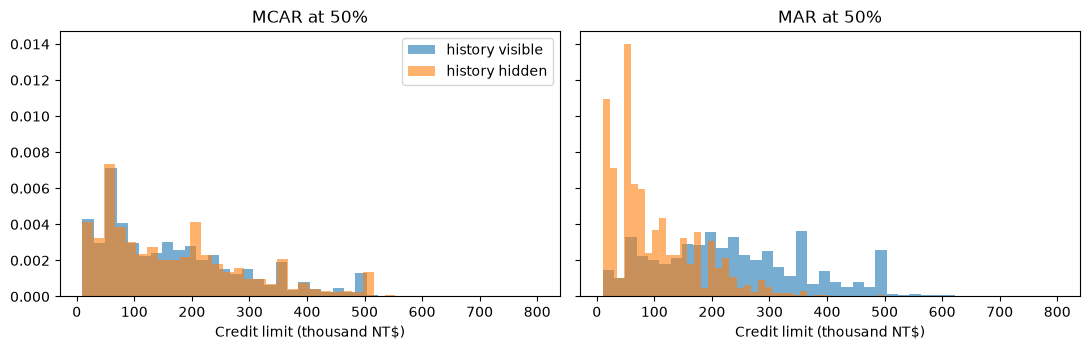

In [4]:
# Credit-limit distributions of borrowers with visible vs hidden history, at a 50% rate
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, mech in zip(axes, ["MCAR", "MAR"]):
    m = history_mask(train, mech, 0.5, np.random.default_rng(1), stats)
    ax.hist(train.loc[~m, "LIMIT_BAL"] / 1000, bins=40, alpha=0.6, density=True, label="history visible")
    ax.hist(train.loc[m, "LIMIT_BAL"] / 1000, bins=40, alpha=0.6, density=True, label="history hidden")
    ax.set_title(f"{mech} at 50%"); ax.set_xlabel("Credit limit (thousand NT$)")
axes[0].legend(); plt.tight_layout(); plt.show()

## 2. What a thin-file borrower looks like after masking

In [5]:
# Apply a MAR mask to 2,000 borrowers and show five thin-file rows:
# history is NaN and flagged in hist_missing, while profile and transactional fields are untouched
mask = history_mask(train.head(2000), "MAR", 0.5, np.random.default_rng(2), stats)
masked = apply_history_mask(train.head(2000), mask)
masked.loc[mask, [FLAG, "PAY_0", "PAY_2", "PAY_6", "LIMIT_BAL", "BILL_AMT1"]].head(5)

,hist_missing,PAY_0,PAY_2,PAY_6,LIMIT_BAL,BILL_AMT1
0,1,NaN,NaN,NaN,50000.0,48785.0
1,1,NaN,NaN,NaN,50000.0,50175.0
5,1,NaN,NaN,NaN,50000.0,75804.0
6,1,NaN,NaN,NaN,90000.0,106053.0
7,1,NaN,NaN,NaN,60000.0,61514.0


## 3. Sparsity and noise on the transactional block

Keep only the 2 most recent months (later months become NaN):
   BILL_AMT1  BILL_AMT2  BILL_AMT3  PAY_AMT1  PAY_AMT3
0    48785.0    49762.0        NaN    2090.0       NaN
1    50175.0    49798.0        NaN    1796.0       NaN
2     5086.0    14180.0        NaN   14180.0       NaN
3     7789.0     9656.0        NaN    9666.0       NaN
4      488.0      878.0        NaN     878.0       NaN


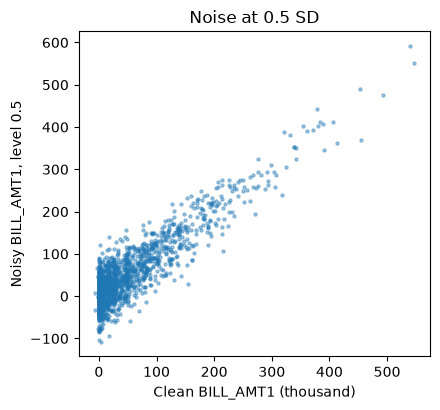

In [6]:
# Sparsity: with 2 months kept, month-3 fields (BILL_AMT3, PAY_AMT3) become NaN
print("Keep only the 2 most recent months (later months become NaN):")
display_cols = ["BILL_AMT1", "BILL_AMT2", "BILL_AMT3", "PAY_AMT1", "PAY_AMT3"]
print(sparsify_transactional(train.head(5), 2)[display_cols])

# Noise: compare clean vs noisy values; level 0.5 adds Gaussian error with SD = 0.5 x the variable's SD
clean = train.sample(1500, random_state=0)
noisy = add_noise(clean, 0.5, np.random.default_rng(3), stats["trans_sd"])
plt.figure(figsize=(4.5, 4.2))
plt.scatter(clean["BILL_AMT1"] / 1000, noisy["BILL_AMT1"] / 1000, s=5, alpha=0.4)
plt.xlabel("Clean BILL_AMT1 (thousand)"); plt.ylabel("Noisy BILL_AMT1, level 0.5")
plt.title("Noise at 0.5 SD"); plt.tight_layout(); plt.show()

## 4. Unit tests

In [7]:
# Run the project's unit tests; skipped with a message if pytest is not installed
import importlib.util, subprocess
if importlib.util.find_spec("pytest") is None:
    print("pytest is not installed in this environment: run  pip install pytest  and re-run this cell.")
else:
    out = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT, capture_output=True, text=True)
    print(out.stdout[-1500:] or out.stderr[-1500:])

........                                                                 [100%]
8 passed in 5.06s

